# 🎯 Notebook 03 — Percepções para Regressão

### Dataset: Cardiovascular Disease Prediction
### Disciplina: DCT1401 — Inteligência Artificial (UFRN)
### Aluna: Mariana dos Santos Batista Medeiros — Matrícula: 20230083988

Este notebook analisa o conjunto de dados preparado no Notebook 02 com foco no problema de **regressão**.

Nesta etapa serão realizadas:

1. Carregamento do dataset processado para regressão
2. Identificação e justificativa da variável alvo
3. Análise da distribuição e variabilidade do target
4. Análise da relação entre as features e o target
5. Identificação das features mais associadas ao target
6. Percepções, desafios e recomendações para modelagem

O objetivo deste notebook não é treinar um modelo definitivo, mas identificar quais variáveis parecem mais relevantes para um futuro problema de regressão.

In [1]:
# Manipulação de dados
import pandas as pd

# Visualização
import matplotlib.pyplot as plt
import seaborn as sns

# Organização dos caminhos do projeto
from pathlib import Path


# Configurações visuais
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
pd.set_option("display.max_columns", 50)


# ---------------------------------------------------------
# Localização automática da raiz do projeto
# ---------------------------------------------------------

diretorio_atual = Path.cwd()

if diretorio_atual.name == "notebooks":
    raiz_projeto = diretorio_atual.parent

elif (diretorio_atual / "data" / "processed").exists():
    raiz_projeto = diretorio_atual

else:
    raise FileNotFoundError(
        "Não foi possível localizar a estrutura do projeto."
    )


# ---------------------------------------------------------
# Caminhos utilizados
# ---------------------------------------------------------

caminho_regressao = (
    raiz_projeto
    / "data"
    / "processed"
    / "dataset_regression.csv"
)

pasta_figuras = raiz_projeto / "reports" / "figures"
pasta_figuras.mkdir(parents=True, exist_ok=True)


print("Bibliotecas carregadas com sucesso!")
print(f"Raiz do projeto: {raiz_projeto}")

Bibliotecas carregadas com sucesso!
Raiz do projeto: c:\Users\farma\OneDrive\Documentos\IA\projeto_cardiovascular


---
## 📁 1. Carregamento do Dataset Processado para Regressão

O Notebook 02 realizou a limpeza e o pré-processamento dos dados e gerou o arquivo `dataset_regression.csv`.

Essa versão contém as features já tratadas e codificadas, com as **16 variáveis quantitativas padronizadas pelo StandardScaler**. O arquivo mantém `Risk_Score` como variável alvo da regressão e não inclui `Cardiovascular_Disease`, conforme definido na etapa anterior.

As variáveis categóricas codificadas foram preservadas em suas representações numéricas e `Risk_Score` foi mantido em sua escala original.

Por isso, nenhum tratamento, codificação ou padronização será repetido neste notebook.

In [2]:
# Carregamento do dataset preparado no Notebook 02
df = pd.read_csv(caminho_regressao)

print(
    f"Dataset carregado: "
    f"{df.shape[0]} linhas x {df.shape[1]} colunas"
)

print(
    "Valores ausentes:",
    df.isnull().sum().sum()
)

print(
    "Colunas textuais:",
    df.select_dtypes(include="object").columns.tolist()
)

print(
    "Risk_Score presente:",
    "Risk_Score" in df.columns
)

print(
    "Cardiovascular_Disease presente:",
    "Cardiovascular_Disease" in df.columns
)

df.head()

Dataset carregado: 20000 linhas x 36 colunas
Valores ausentes: 0
Colunas textuais: []
Risk_Score presente: True
Cardiovascular_Disease presente: False


,Age,Gender,Height_cm,Weight_kg,BMI,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Heart_Rate,Cholesterol,HDL,LDL,Triglycerides,Blood_Glucose,Diabetes,Hypertension,Smoking,Alcohol_Consumption,Physical_Activity,Exercise_Days_Per_Week,Daily_Walking_Minutes,Sleep_Hours,Stress_Level,Family_History,Chest_Pain,Shortness_of_Breath,ECG_Result,Medication,Diet_Quality,Annual_Income_USD,Education_Level,BMI_Category,Risk_Score,Region_East,Region_North,Region_South,Region_West
0,-0.604930,0,-0.244301,1.136970,1.085015,-0.384491,-0.050595,1.052636,1.090643,-0.722347,-0.020672,1.838329,-0.454229,0,0,1,0,1,1.528986,-0.107776,1.170423,2,0,0,0,0,0,1,0.056754,1,3,7.63,0,0,0,0
1,-0.499972,0,-0.496768,-2.173125,-1.762031,-0.611338,-2.090550,-0.149747,0.356960,0.238860,-0.704551,0.448452,-1.105517,0,0,0,0,1,-0.660033,-0.511923,-0.005464,0,0,0,1,0,0,0,-1.379411,2,0,2.96,0,1,0,0
2,-0.814846,0,-1.415746,1.623351,2.402790,0.125914,-0.475586,-0.650740,0.356960,-2.164156,-0.377479,1.416088,0.450336,0,0,1,1,0,0.653378,0.642783,0.543283,1,0,0,0,0,0,0,-0.992920,1,3,9.73,0,0,1,0
3,1.494228,0,0.068757,0.042612,-0.037535,0.693031,0.629390,-0.450342,-1.287500,-0.379059,-0.526148,0.993847,-0.020038,1,0,1,0,1,0.215575,1.479945,0.778461,1,1,1,1,0,1,1,1.229963,1,2,15.81,0,0,0,1
4,-1.077241,0,0.876650,-1.288181,-1.436654,1.090013,-0.050595,-0.851137,0.508757,0.238860,-0.704551,-0.255282,0.558884,0,1,1,0,1,0.653378,-0.107776,-0.397426,1,1,0,0,0,1,1,-0.254270,0,0,9.40,0,0,0,1


> **Observação:** valores negativos que possam aparecer em variáveis quantitativas como `Age`, `BMI` ou `Blood_Glucose` não representam valores físicos negativos. Eles são resultado da padronização pelo StandardScaler: valores abaixo da média da variável ficam negativos e valores acima da média ficam positivos. O target `Risk_Score` permanece em sua escala original.

---
## 🎯 2. Identificação e Justificativa da Variável Alvo

### Variável escolhida: `Risk_Score`

A variável `Risk_Score` foi escolhida como target para o problema de regressão pelos seguintes motivos:

**1. Natureza da variável:** `Risk_Score` é uma variável numérica contínua, característica compatível com um problema de regressão.

**2. Variabilidade:** a variável apresenta amplitude e dispersão suficientes para permitir a investigação de relações com outras características do conjunto de dados.

**3. Coerência com o problema:** semanticamente, a variável representa um escore numérico relacionado ao risco cardiovascular. Portanto, estimar seu valor a partir das demais características constitui um problema compatível com regressão.

**4. Relação com as features:** nas próximas seções será avaliado, por meio de correlações e visualizações, quais características apresentam maior associação com `Risk_Score`.

A escolha é, portanto, baseada no tipo da variável, em sua variabilidade e no significado que ela possui dentro do conjunto de dados.

### 2.1 Distribuição e variabilidade do target

Estatísticas descritivas do Risk_Score:
count    20000.00
mean         9.84
std          4.18
min         -1.61
25%          6.86
50%          9.62
75%         12.59
max         27.10
Name: Risk_Score, dtype: float64

Mediana: 9.62
Assimetria: 0.304


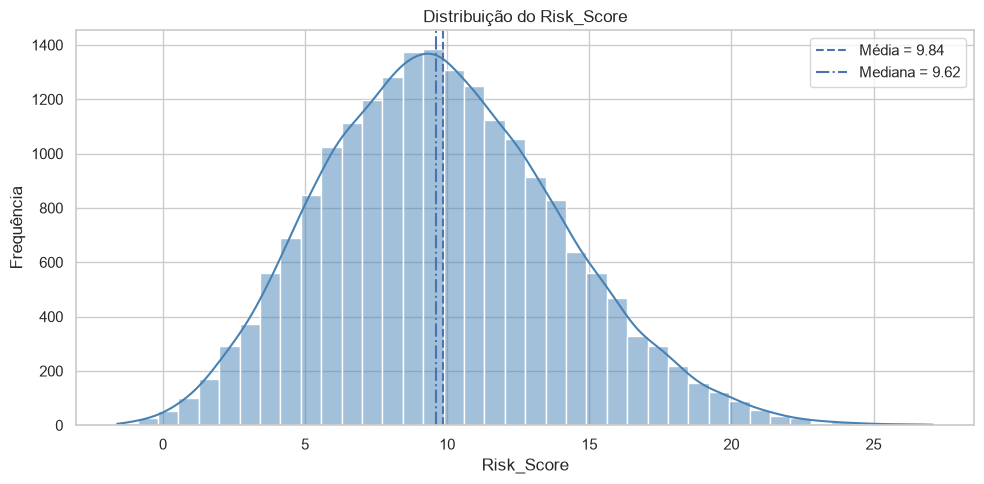

In [3]:
# Estatísticas do Risk_Score
estatisticas_target = df["Risk_Score"].describe()

print("Estatísticas descritivas do Risk_Score:")
print("=" * 50)
print(estatisticas_target.round(2))

print(
    f"\nMediana: "
    f"{df['Risk_Score'].median():.2f}"
)

print(
    f"Assimetria: "
    f"{df['Risk_Score'].skew():.3f}"
)


# Distribuição do target
plt.figure(figsize=(10, 5))

sns.histplot(
    df["Risk_Score"],
    bins=40,
    kde=True,
    color="steelblue"
)

plt.axvline(
    df["Risk_Score"].mean(),
    linestyle="--",
    label=f"Média = {df['Risk_Score'].mean():.2f}"
)

plt.axvline(
    df["Risk_Score"].median(),
    linestyle="-.",
    label=f"Mediana = {df['Risk_Score'].median():.2f}"
)

plt.title("Distribuição do Risk_Score")
plt.xlabel("Risk_Score")
plt.ylabel("Frequência")
plt.legend()

plt.tight_layout()

plt.savefig(
    pasta_figuras / "risk_score_distribution.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

> 💡 **Interpretação:** `Risk_Score` apresenta variabilidade considerável, com média próxima da mediana e leve assimetria positiva. A distribuição não é concentrada em um único valor, o que reforça sua adequação como variável contínua para a análise de regressão.

---
## 📊 3. Relação entre Features e Target (Risk_Score)

### 3.1 Correlação das features com o target

In [4]:
# Todas as colunas, exceto o target, são candidatas a features
features = [
    col for col in df.columns
    if col != "Risk_Score"
]

# Correlação de Pearson de cada feature com o target
correlacoes = (
    df[features + ["Risk_Score"]]
    .corr()["Risk_Score"]
    .drop("Risk_Score")
)

# Ordenação pela magnitude da correlação
ranking_correlacoes = (
    pd.DataFrame({
        "Correlação": correlacoes,
        "Correlação Absoluta": correlacoes.abs()
    })
    .sort_values(
        "Correlação Absoluta",
        ascending=False
    )
)

print("Features mais associadas ao Risk_Score:")

display(
    ranking_correlacoes
    .head(15)
    .round(3)
)

Features mais associadas ao Risk_Score:


,Correlação,Correlação Absoluta
Diabetes,0.400,0.400
Hypertension,0.357,0.357
ECG_Result,0.309,0.309
Blood_Glucose,0.304,0.304
Chest_Pain,0.291,0.291
Blood_Pressure_Systolic,0.263,0.263
Family_History,0.229,0.229
Smoking,0.212,0.212
Shortness_of_Breath,0.189,0.189
Age,0.189,0.189


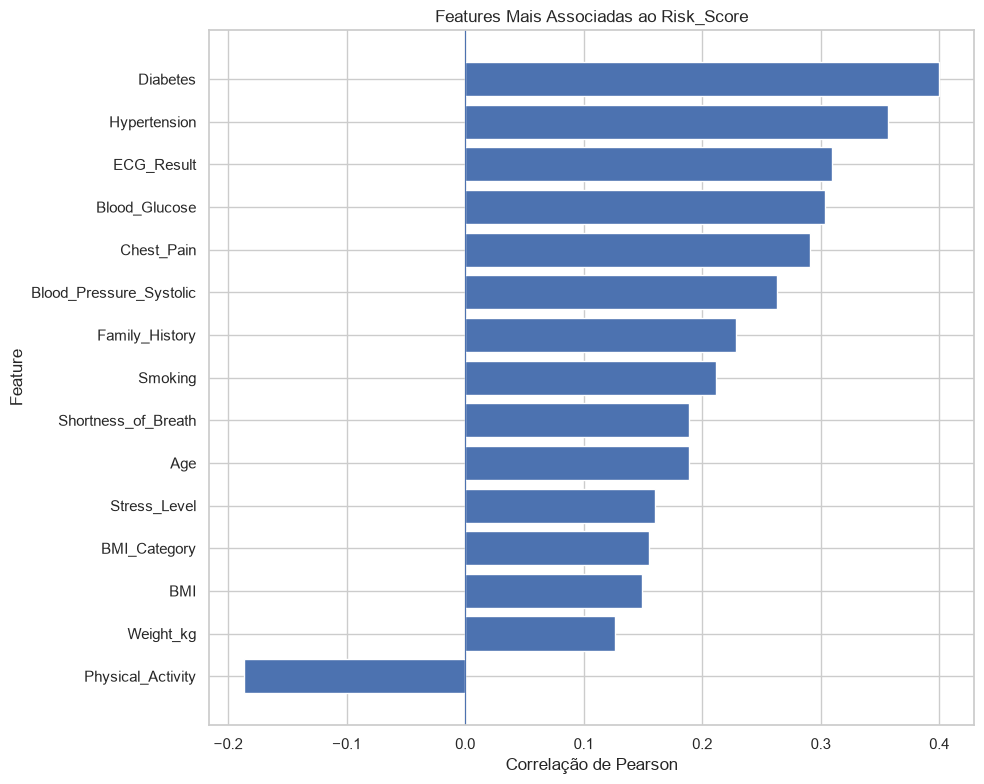

Gráfico salvo em: reports/figures/correlation_with_risk_score.png


In [5]:
top15 = (
    ranking_correlacoes
    .head(15)
    .sort_values("Correlação")
)

plt.figure(figsize=(10, 8))

plt.barh(
    top15.index,
    top15["Correlação"]
)

plt.axvline(
    0,
    linewidth=0.8
)

plt.title(
    "Features Mais Associadas ao Risk_Score"
)

plt.xlabel("Correlação de Pearson")
plt.ylabel("Feature")

plt.tight_layout()

plt.savefig(
    pasta_figuras / "correlation_with_risk_score.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print(
    "Gráfico salvo em: "
    "reports/figures/correlation_with_risk_score.png"
)

> 💡 **Interpretação:** As maiores correlações com `Risk_Score` são observadas em `Diabetes`, `Hypertension`, `ECG_Result`, `Blood_Glucose`, `Chest_Pain` e `Blood_Pressure_Systolic`. Entretanto, nenhuma feature apresenta individualmente correlação linear muito elevada com o target; a maior é aproximadamente 0,40.
>
> Isso sugere que o comportamento de `Risk_Score` pode depender da combinação de várias características e também de relações que não sejam estritamente lineares.
>
> Entre as associações negativas, destaca-se `Physical_Activity`, com correlação aproximada de -0,19. Como algumas variáveis categóricas foram codificadas numericamente, essas correlações devem ser interpretadas como associações exploratórias e não como relações causais.
>
> A padronização das variáveis quantitativas realizada no Notebook 02 não altera os coeficientes de correlação de Pearson, pois consiste em uma transformação linear de escala. Assim, é esperado que as associações lineares observadas permaneçam equivalentes após a padronização.

### 3.2 Relação entre features quantitativas e Risk_Score

Para visualizar a relação entre as variáveis quantitativas e o target, serão selecionadas as quatro features quantitativas com maior correlação absoluta com `Risk_Score`.

Como essas features foram padronizadas no Notebook 02, seus valores são apresentados em **unidades padronizadas (Z-score)**. A padronização altera a escala dos valores, mas preserva a forma das relações e as correlações lineares com o target.

In [6]:
# Variáveis quantitativas contínuas/discretas do dataset
variaveis_quantitativas = [
    "Age",
    "Height_cm",
    "Weight_kg",
    "BMI",
    "Blood_Pressure_Systolic",
    "Blood_Pressure_Diastolic",
    "Heart_Rate",
    "Cholesterol",
    "HDL",
    "LDL",
    "Triglycerides",
    "Blood_Glucose",
    "Exercise_Days_Per_Week",
    "Daily_Walking_Minutes",
    "Sleep_Hours",
    "Annual_Income_USD"
]

# Selecionar as quatro quantitativas mais correlacionadas
top4_quantitativas = (
    correlacoes[variaveis_quantitativas]
    .abs()
    .sort_values(ascending=False)
    .head(4)
    .index
    .tolist()
)

print(
    "Variáveis quantitativas selecionadas:",
    top4_quantitativas
)

Variáveis quantitativas selecionadas: ['Blood_Glucose', 'Blood_Pressure_Systolic', 'Age', 'BMI']


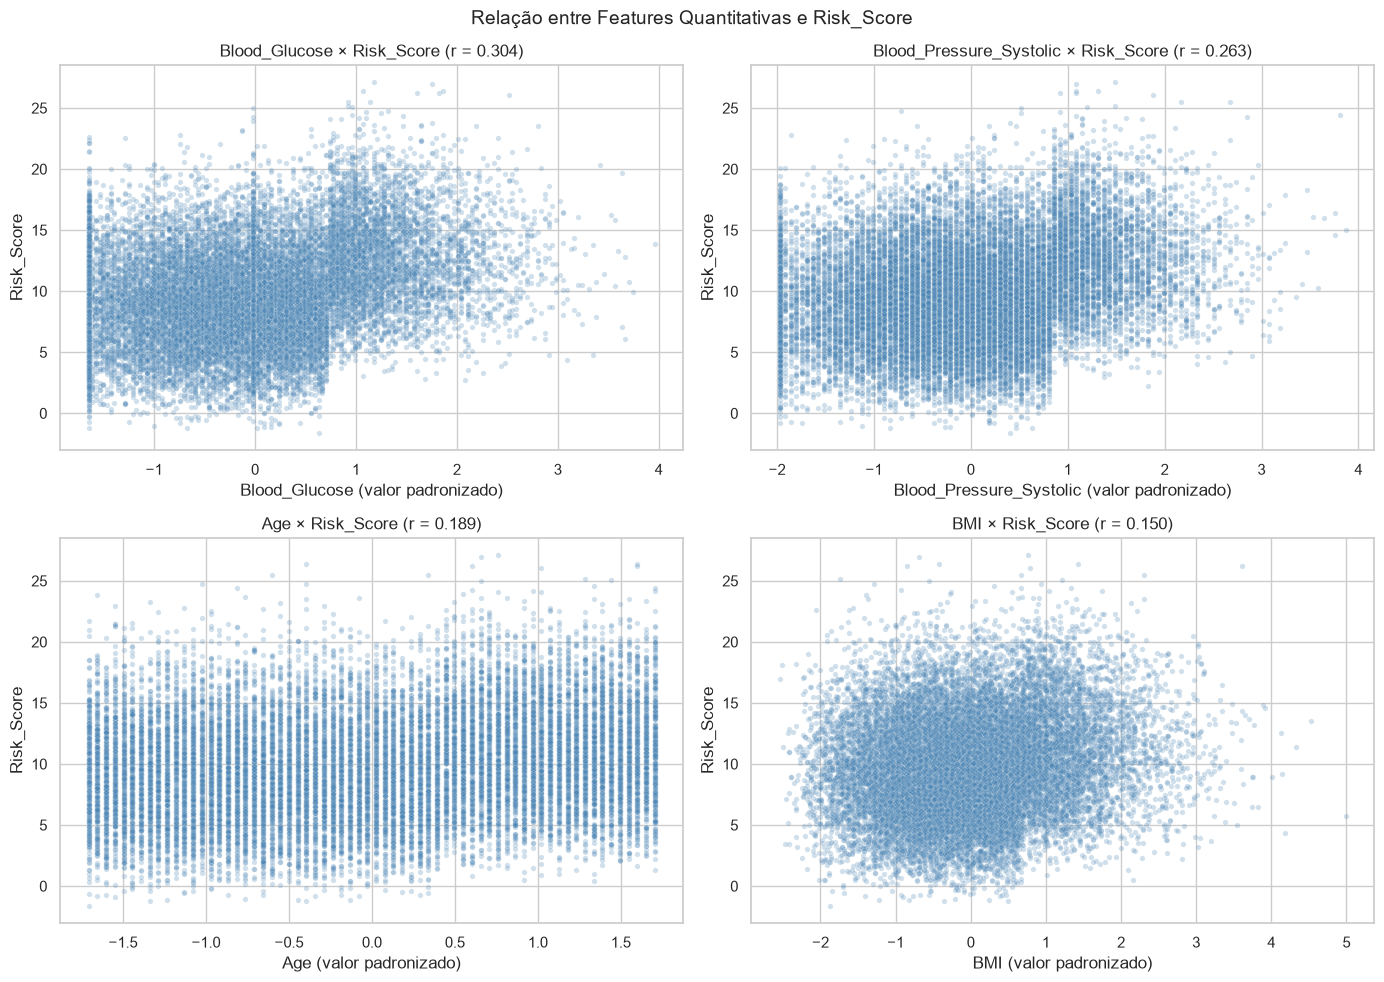

In [7]:
fig, axes = plt.subplots(
    2,
    2,
    figsize=(14, 10)
)

for ax, feature in zip(
    axes.ravel(),
    top4_quantitativas
):

    sns.scatterplot(
        data=df,
        x=feature,
        y="Risk_Score",
        alpha=0.25,
        s=15,
        ax=ax,
        color="steelblue"
    )

    r = correlacoes[feature]

    ax.set_title(
        f"{feature} × Risk_Score "
        f"(r = {r:.3f})"
    )

    ax.set_xlabel(
        f"{feature} (valor padronizado)"
    )

    ax.set_ylabel(
        "Risk_Score"
    )

plt.suptitle(
    "Relação entre Features Quantitativas e Risk_Score",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    pasta_figuras / "scatter_features_vs_risk.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

### 3.3 Risk_Score por features binárias



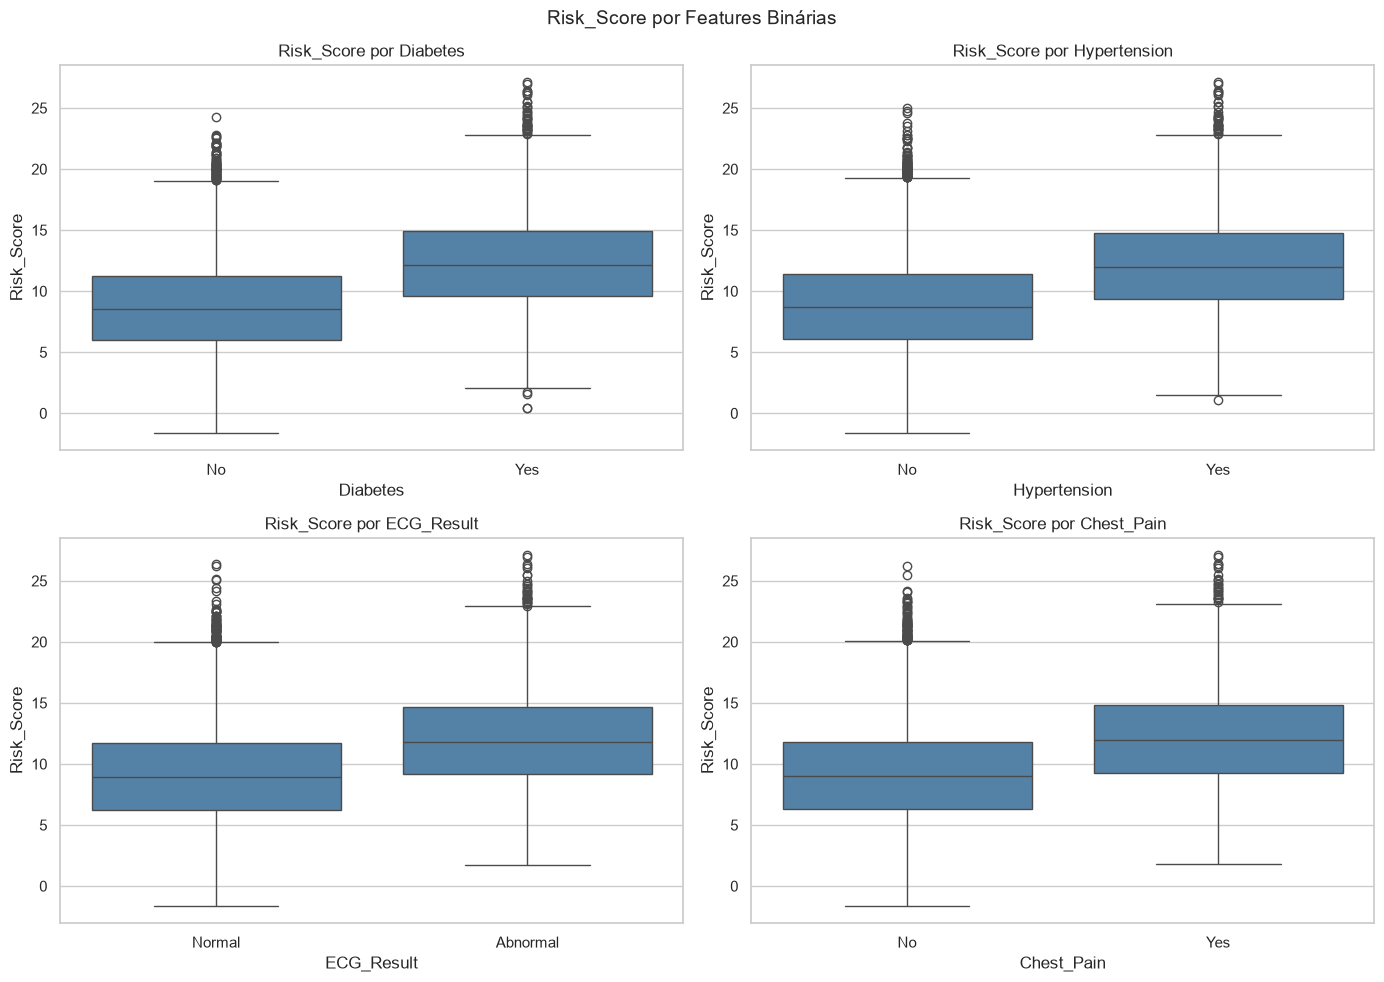

In [8]:
variaveis_binarias = [
    "Diabetes",
    "Hypertension",
    "ECG_Result",
    "Chest_Pain"
]

rotulos = {
    "Diabetes": ["No", "Yes"],
    "Hypertension": ["No", "Yes"],
    "ECG_Result": ["Normal", "Abnormal"],
    "Chest_Pain": ["No", "Yes"]
}

fig, axes = plt.subplots(
    2,
    2,
    figsize=(14, 10)
)

for ax, var in zip(
    axes.ravel(),
    variaveis_binarias
):

    sns.boxplot(
        data=df,
        x=var,
        y="Risk_Score",
        ax=ax,
        color="steelblue"
    )

    ax.set_xticks([0, 1])
    ax.set_xticklabels(rotulos[var])

    ax.set_title(
        f"Risk_Score por {var}"
    )

plt.suptitle(
    "Risk_Score por Features Binárias",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    pasta_figuras / "boxplot_risk_by_binary_features.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

---
## 🔎 4. Seleção das Features Prioritárias

A análise anterior permitiu identificar as variáveis com maior associação ao `Risk_Score`.

Considerando a necessidade de manter um conjunto reduzido e representativo de variáveis para as próximas etapas, foram selecionadas as **seis features com maiores correlações em valor absoluto** com o target.

Essa redução busca concentrar a análise nas variáveis que apresentaram maior associação com `Risk_Score`, evitando um conjunto excessivamente amplo de entradas.

In [9]:
features_prioritarias = (
    ranking_correlacoes
    .head(6)
    [["Correlação"]]
)

features_prioritarias.round(3)

,Correlação
Diabetes,0.400
Hypertension,0.357
ECG_Result,0.309
Blood_Glucose,0.304
Chest_Pain,0.291
Blood_Pressure_Systolic,0.263


> 💡 **Features prioritárias:** `Diabetes`, `Hypertension`, `ECG_Result`, `Blood_Glucose`, `Chest_Pain` e `Blood_Pressure_Systolic`.
>
> Essas seis variáveis apresentaram as maiores associações com `Risk_Score` no conjunto analisado e formam um núcleo reduzido para orientar as próximas etapas.
>
> Essa seleção é exploratória e não significa que as demais variáveis sejam irrelevantes; elas permanecem disponíveis caso análises posteriores indiquem necessidade de incorporá-las.

---
## 📝 5. Percepções e Recomendações para Modelagem — Regressão

### Features recomendadas

Considerando as correlações observadas e a necessidade de manter um conjunto enxuto de variáveis, recomenda-se inicialmente o seguinte núcleo de features:

- `Diabetes`
- `Hypertension`
- `ECG_Result`
- `Blood_Glucose`
- `Chest_Pain`
- `Blood_Pressure_Systolic`

Essas variáveis apresentaram as seis maiores associações com `Risk_Score`, com correlações variando aproximadamente entre 0,26 e 0,40.

Nenhuma delas apresenta isoladamente uma correlação linear muito elevada com o target. Portanto, a seleção busca reunir um conjunto reduzido e fundamentado nos dados para orientar análises e modelagens posteriores.

### Possíveis desafios

**1. Relações não lineares:** as correlações individuais são moderadas ou fracas, portanto parte da relação entre features e target pode não ser estritamente linear.

**2. Multicolinearidade:** no conjunto completo, `BMI` e `Weight_kg` apresentaram forte correlação entre si (aproximadamente 0,86). Caso ambas sejam utilizadas em modelos lineares, essa redundância deverá ser considerada.

**3. Outliers:** os valores extremos identificados no Notebook 02 foram mantidos por não haver evidências suficientes de erro. Alguns algoritmos podem ser mais sensíveis a essas observações.

### Algoritmos sugeridos

| Algoritmo | Justificativa |
|---|---|
| **Regressão Linear** | Pode servir como modelo inicial simples e interpretável |
| **Ridge / Lasso** | Alternativas lineares regularizadas, úteis caso haja redundância entre preditores ou outras features sejam incorporadas |
| **Random Forest Regressor** | Permite representar relações não lineares e interações entre variáveis |
| **Gradient Boosting Regressor** | Outra alternativa para relações não lineares e combinações mais complexas de features |

Em uma etapa futura de modelagem, os algoritmos poderão ser comparados utilizando divisão entre treino e teste e métricas adequadas para regressão, como **MAE**, **RMSE** e **R²**.

Em síntese, Risk_Score mostrou-se adequado como variável alvo para o problema de regressão, e as análises realizadas destacaram Diabetes, Hypertension, ECG_Result, Blood_Glucose, Chest_Pain e Blood_Pressure_Systolic como features prioritárias. Como as correlações individuais são moderadas, relações não lineares e a combinação entre diferentes características podem ser relevantes para a modelagem. Também devem ser considerados os outliers mantidos e possíveis redundâncias entre variáveis. Como modelos iniciais, podem ser avaliados Regressão Linear, Ridge/Lasso, Random Forest Regressor e Gradient Boosting Regressor.